### SCIENTIFIC COMPUTING – SECOND LAB


# **Brief context:**

This notebook uses the Tree Growth dataset from a case study published in the September 1995 issue of the Canadian Journal of Statistics, which studied the effects of the growth regulators paclobutrazol (PP 333) and flurprimidol (EL-500) on the number and length of internodes in terminal sprouts formed on trimmed silver maple trees. The regulators were injected into the tree trunks in May 1985, and the sprouts were collected in January 1987. The dataset has 2,796 rows, where each row is a terminal sprout, and for each sprout the total length (TL), the number of internodes (IN), and the length of up to 29 consecutive internodes were measured. The sprouts are divided into 6 treatments: two control groups, a standard control and a methanol control that only contains the solvent, and four experimental groups that combine the type of regulator (PP 333 or EL-500) with a dose of 4 g/L or 20 g/L. The goal of this analysis is to determine whether the treatments change the growth pattern of the sprouts and how well the groups can be distinguished using the extracted features. The data were provided by Dr. Fernando Camacho of Ontario Hydro Technologies.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import f_oneway, shapiro, kruskal
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score


# **Advanced data handling with Pandas**

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/anmagugos1501-eng/SCIENTIFIC-COMPUTING---assignments/main/cjs.csv') #This is the RUTE of the data

In [3]:
#In this case we start to see how the data work, just 4 see what happent n what we can do
#with the information
df.head()
df.dtypes

,0
N,int64
TR,object
TREE,object
BR,object
TL,float64
IN,int64
INTERNODE_1,float64
INTERNODE_2,object
INTERNODE_3,object
INTERNODE_4,object


In [4]:
df.loc[:, 'INTERNODE_2':'INTERNODE_29'] #The column view displays the internode data, showing the presence of question marks (?). This serves as evidence as to why these columns were parsed as text

,INTERNODE_2,INTERNODE_3,INTERNODE_4,INTERNODE_5,INTERNODE_6,INTERNODE_7,INTERNODE_8,INTERNODE_9,INTERNODE_10,INTERNODE_11,...,INTERNODE_20,INTERNODE_21,INTERNODE_22,INTERNODE_23,INTERNODE_24,INTERNODE_25,INTERNODE_26,INTERNODE_27,INTERNODE_28,INTERNODE_29
0,2.3,7.4,8.6,6.7,7.2,6.6,6.2,5.5,5.0,5.4,...,?,?,?,?,?,?,?,?,?,?
1,1.3,4.0,5.2,2.8,2.2,1.5,?,?,?,?,...,?,?,?,?,?,?,?,?,?,?
2,1.0,4.3,8.8,6.8,7.6,6.2,4.7,3.5,2.2,0.5,...,?,?,?,?,?,?,?,?,?,?
3,1.2,3.5,4.2,2.2,2.8,1.5,0.1,?,?,?,...,?,?,?,?,?,?,?,?,?,?
4,1.0,3.5,8.2,5.3,6.2,4.8,4.7,3.1,3.8,3.3,...,?,?,?,?,?,?,?,?,?,?
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2791,0.3,0.3,0.3,?,?,?,?,?,?,?,...,?,?,?,?,?,?,?,?,?,?
2792,0.3,0.3,0.3,?,?,?,?,?,?,?,...,?,?,?,?,?,?,?,?,?,?
2793,0.3,0.3,0.3,?,?,?,?,?,?,?,...,?,?,?,?,?,?,?,?,?,?
2794,0.2,0.2,0.2,?,?,?,?,?,?,?,...,?,?,?,?,?,?,?,?,?,?


The parameter change was made because operations cannot be performed on object-type characters such as '?'. Therefore, we replaced these data points with NaN.

In [5]:
df = df.apply(lambda col: col.map(lambda x: np.nan if x == '?' else x))
cols = df.loc[:, 'INTERNODE_2':'INTERNODE_29'].columns # Convert the internode columns from text to numbers
df[cols] = df[cols].astype(float)
df.dtypes

,0
N,int64
TR,object
TREE,object
BR,object
TL,float64
IN,int64
INTERNODE_1,float64
INTERNODE_2,float64
INTERNODE_3,float64
INTERNODE_4,float64


In [6]:
df.loc[:, 'INTERNODE_2':'INTERNODE_29']# verify that the '?' marks were replaced with NaN

,INTERNODE_2,INTERNODE_3,INTERNODE_4,INTERNODE_5,INTERNODE_6,INTERNODE_7,INTERNODE_8,INTERNODE_9,INTERNODE_10,INTERNODE_11,...,INTERNODE_20,INTERNODE_21,INTERNODE_22,INTERNODE_23,INTERNODE_24,INTERNODE_25,INTERNODE_26,INTERNODE_27,INTERNODE_28,INTERNODE_29
0,2.3,7.4,8.6,6.7,7.2,6.6,6.2,5.5,5.0,5.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.3,4.0,5.2,2.8,2.2,1.5,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,4.3,8.8,6.8,7.6,6.2,4.7,3.5,2.2,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2,3.5,4.2,2.2,2.8,1.5,0.1,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.0,3.5,8.2,5.3,6.2,4.8,4.7,3.1,3.8,3.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2791,0.3,0.3,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2792,0.3,0.3,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2793,0.3,0.3,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2794,0.2,0.2,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.isna().sum() #count the missing values per column

,0
N,0
TR,0
TREE,0
BR,12
TL,0
IN,0
INTERNODE_1,0
INTERNODE_2,64
INTERNODE_3,637
INTERNODE_4,1634


Missing values in the original file were marked with '?', so pandas read the columns INTERNODE_2 to INTERNODE_29 as text. These marks were replaced with NaN, and the internode columns were converted to float. Each row is a sprout, and the columns INTERNODE_1 to INTERNODE_29 store the length of each of its internodes; only one sprout has 29 internodes. From INTERNODE_2 to INTERNODE_29, the number of missing values increases, because an internode does not exist when the sprout is shorter. These structural missing values were not filled, since imputing them would add non-existent internodes and distort the distributions and statistics of the internode lengths. In contrast, the BR column has 12 missing values, which are truly missing data: the branch existed, but it was not recorded.

In [8]:
# Convert the label columns (treatment, tree and branch) to the category type
categorical_columns = ['TR', 'TREE', 'BR']
df[categorical_columns] = df[categorical_columns].astype('category')
df.dtypes

,0
N,int64
TR,category
TREE,category
BR,category
TL,float64
IN,int64
INTERNODE_1,float64
INTERNODE_2,float64
INTERNODE_3,float64
INTERNODE_4,float64


In [9]:
#encode the treatment, class variable, as integers from 0 to 5
label_encoder = LabelEncoder()
y_le = label_encoder.fit_transform(df['TR'])
df['TR_code'] = y_le
df.head()

,N,TR,TREE,BR,TL,IN,INTERNODE_1,INTERNODE_2,INTERNODE_3,INTERNODE_4,...,INTERNODE_21,INTERNODE_22,INTERNODE_23,INTERNODE_24,INTERNODE_25,INTERNODE_26,INTERNODE_27,INTERNODE_28,INTERNODE_29,TR_code
0,1,control,G28,A,75.0,15,1.0,2.3,7.4,8.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
1,2,control,G28,B,18.0,7,0.7,1.3,4.0,5.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
2,3,control,G28,C,46.0,11,0.5,1.0,4.3,8.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
3,4,control,G28,C,16.0,8,0.5,1.2,3.5,4.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
4,5,control,G28,D,56.0,16,0.5,1.0,3.5,8.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4


The variables TR (treatment), TREE (tree), and BR (branch) are not measurements but identifying labels, so they were converted to the category type, which saves memory and gives meaning to columns with a limited number of possible values. Since TR is the class variable of the analysis, LabelEncoder was used to transform its text labels into numbers, which are needed for the statistical tests and the AUC calculation. This created a new column, TR_code, with values from 0 to 5 assigned in alphabetical order: EL_500_20g/L = 0, EL_500_4g/L = 1, PP_333_20g/L = 2, PP_333_4g/L = 3, control = 4, and methanol_control = 5. Finally, the 12 sprouts without information in BR were kept, because this variable is not used in the analysis and these sprouts have complete internode data.

Data coherence review and inconsistencies: the IN column records the number of internodes of each sprout, so it should match the number of internode columns with data. This check found only one inconsistent sprout (N = 1067), where IN is 3 but four internodes have values of 0.3 cm. The total length (TL = 1.0 cm) cannot tell which value is correct, because 3 × 0.3 = 0.9 and 4 × 0.3 = 1.2 both round to 1 cm. Since it is only 1 of 2,796 sprouts, it was removed.



In [10]:
#In this case we check if the data makes sense. IN says how many internodes
#sprout has, so, I count the internodes that have the value n compare bot numbers
internode_cols = df.loc[:, 'INTERNODE_1':'INTERNODE_29'].columns
df['IN_count'] = df[internode_cols].notna().sum(axis=1)
df[df['IN'] != df['IN_count']]

,N,TR,TREE,BR,TL,IN,INTERNODE_1,INTERNODE_2,INTERNODE_3,INTERNODE_4,...,INTERNODE_22,INTERNODE_23,INTERNODE_24,INTERNODE_25,INTERNODE_26,INTERNODE_27,INTERNODE_28,INTERNODE_29,TR_code,IN_count
1066,1067,PP_333_20g/L,M10,G,1.0,3,0.3,0.3,0.3,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,4


In [11]:
df = df[df['N'] != 1067] # Only one sprout, N = 1067, has a problem: IN says 3,
#but it has 4 internodes.
# TL can't tell me which one is right, so I remove this sprout (it's only 1 of 2796)

# I don't need IN_count anymore, so I delete it
df = df.drop(columns='IN_count')
df.shape

(2795, 36)

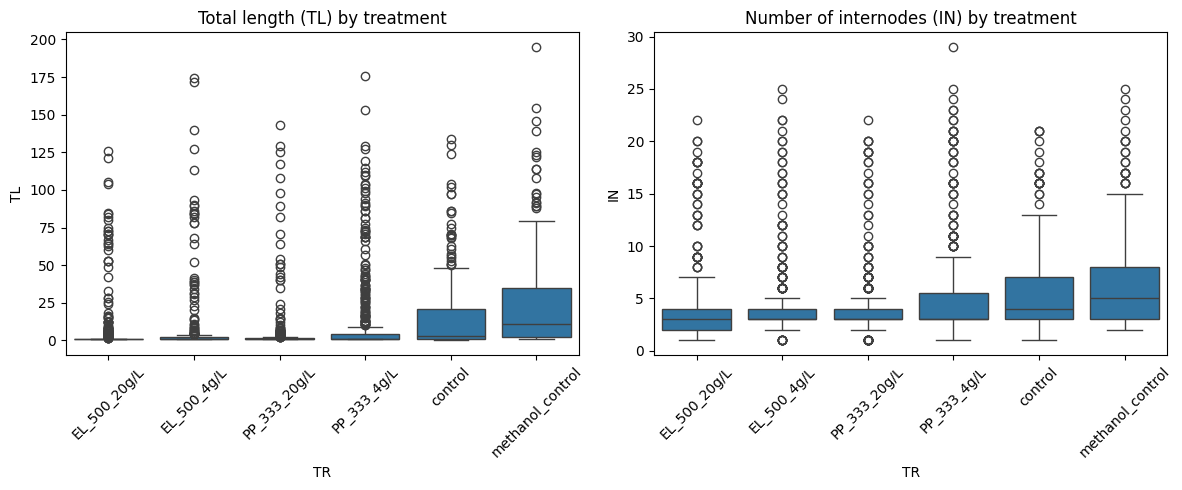

In [12]:
# Boxplots to compare TL and IN between treatments and look for outliers

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='TR', y='TL', data=df)
plt.title('Total length (TL) by treatment')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(x='TR', y='IN', data=df)
plt.title('Number of internodes (IN) by treatment')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Here's what this shows:** I used plt.subplot(1, 2, 1) to divide the figure into 1 row and 2 columns, plotting on the first position. Each box represents a treatment, and the individual scattered points are the outliers.

To evaluate the total sprout length (TL) and the number of internodes (IN), boxplots were constructed for each treatment group to inspect the data distribution and identify potential outliers. Two key findings emerged:

1. Treated groups: they showed a marked concentration of short sprouts (with a median around 1 cm) and numerous outliers above the box. Because almost all sprouts in these groups are close to 1 cm, the box is extremely small, causing any slightly longer sprout to be flagged as an outlier. This pattern reflects the highly skewed shape of the distribution rather than data errors.

2. Control groups: they exhibited considerably longer sprouts and a higher overall variance.

Despite these outliers, they were retained in the analysis rather than discarded, as they represent biologically plausible observations. Removing them would make the treated groups appear artificially uniform, altering the comparison between treatments, which is precisely the effect this analysis intends to measure.

In [13]:
df.groupby('TR')[['TL', 'IN']].agg(['mean', 'median', 'std', 'min', 'max'])

/tmp/ipykernel_105690/1457842414.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('TR')[['TL', 'IN']].agg(['mean', 'median', 'std', 'min', 'max'])


TL                                      IN         \
                       mean median        std  min    max      mean median   
TR                                                                           
EL_500_20g/L       4.960069    1.0  15.482140  1.0  126.0  4.000000    3.0   
EL_500_4g/L        7.904692    1.0  23.482888  1.0  174.5  4.624633    3.0   
PP_333_20g/L       3.675994    1.0  13.587459  1.0  143.0  3.686303    3.0   
PP_333_4g/L       11.226027    1.0  25.258862  1.0  176.0  5.007828    3.0   
control           14.252415    3.0  21.939818  0.0  134.0  5.369565    4.0   
methanol_control  23.397810   11.0  31.414524  1.0  195.0  6.664234    5.0   

                                    
                       std min max  
TR                                  
EL_500_20g/L      3.192927   1  22  
EL_500_4g/L       4.093019   1  25  
PP_333_20g/L      2.753968   1  22  
PP_333_4g/L       4.588555   1  29  
control           3.991048   1  21  
methanol_control  4.661081   2  25

This table confirms that the TL distributions of the treated groups are strongly skewed. Specifically, in the treated groups, the mean of TL is substantially higher than the median; for instance, in the PP_333_20g/L treatment, the mean is 3.7 cm while the median is 1.0 cm. This occurs because a few longer sprouts pull the mean upward without affecting the median. Consequently, the median provides a far more accurate representation of the typical sprout length than the mean.


# *Feature extraction using OOP*

Each sprout’s sequence of internode lengths, from base to tip, is treated as a discrete signal. For example, the first sprout begins with short internodes, peaks at 8.6 cm at the fourth internode, and then tapers off, forming an arch. Features were extracted in two domains. In the spatial domain, five features describe the size of the internodes: maximum length, mean, standard deviation, energy, and RMS. In the frequency domain, one feature obtained with the FFT measures how closely the shape of the sprout resembles a smooth arch.

The code follows an object-oriented design based on the S2 Integrator pattern. A base class called FeatureExtractor stores the sequence, and two child classes, SpatialFeatures and FrequencyFeatures, implement their own extraction method. After testing on one sprout, the classes were applied to all 2,795 sprouts, and the six features were added as new columns to the dataframe.

In [14]:
# Parent class: it only saves the internode sequence of one sprout. extract() is empty here. Each child class writes its own version

class FeatureExtractor:
    def __init__(self, seq):
        self.seq = seq

    def extract(self):
        raise NotImplementedError('no rule in class %s' %
                                  self.__class__.__name__)

# Child class 1 (spatial domain): features about the size of the internodes

class SpatialFeatures(FeatureExtractor):
    def extract(self):
        return {'max_length': np.max(self.seq),
                'mean_length': np.mean(self.seq),
                'std_length': np.std(self.seq),
                'energy': np.sum(self.seq**2),
                'rms': np.sqrt(np.mean(self.seq**2))}

# Child class 2, frequency domain: feature about the shape of the sprout

class FrequencyFeatures(FeatureExtractor):
    def extract(self):
        if len(self.seq) < 4 or np.std(self.seq) < 1e-10:
            return {'low_freq_ratio': np.nan}
        spectrum = np.abs(scipy.fft.fft(self.seq))
        half = len(self.seq) // 2
        low_freq_ratio = spectrum[1]**2 / np.sum(spectrum[1:half+1]**2)
        return {'low_freq_ratio': low_freq_ratio}

In [15]:
seq = df.loc[0, internode_cols].dropna().to_numpy().astype(float) # dropna removes the internodes that don't exist, to_numpy() turns it into an array
seq

array([1. , 2.3, 7.4, 8.6, 6.7, 7.2, 6.6, 6.2, 5.5, 5. , 5.4, 5. , 4.4,
       2.6, 0.8])

In [16]:
# Test the classes with the first sprout. Both use extract, but each class has its own version (polymorphism).
# The results should match the values calculated by hand before.
print(SpatialFeatures(seq).extract())
print(FrequencyFeatures(seq).extract())

{'max_length': np.float64(8.6), 'mean_length': np.float64(4.98), 'std_length': np.float64(2.2789471253190583), 'energy': np.float64(449.91), 'rms': np.float64(5.476677825105289)}
{'low_freq_ratio': np.float64(0.59420765395497)}


In [17]:
# Function that gets the 6 features of one sprout (one row)
def extract_features(row):
    seq = row[internode_cols].dropna().to_numpy().astype(float)
    features = {}
# Use both classes and join their results in one dictionary (polymorphism)
    for Extractor in SpatialFeatures, FrequencyFeatures:
        features.update(Extractor(seq).extract())
    return pd.Series(features)

features_df = df.apply(extract_features, axis=1)
df = pd.concat([df, features_df], axis=1)
df.head()

,N,TR,TREE,BR,TL,IN,INTERNODE_1,INTERNODE_2,INTERNODE_3,INTERNODE_4,...,INTERNODE_27,INTERNODE_28,INTERNODE_29,TR_code,max_length,mean_length,std_length,energy,rms,low_freq_ratio
0,1,control,G28,A,75.0,15,1.0,2.3,7.4,8.6,...,NaN,NaN,NaN,4,8.6,4.980000,2.278947,449.91,5.476678,0.594208
1,2,control,G28,B,18.0,7,0.7,1.3,4.0,5.2,...,NaN,NaN,NaN,4,5.2,2.528571,1.482964,60.15,2.931358,0.829399
2,3,control,G28,C,46.0,11,0.5,1.0,4.3,8.8,...,NaN,NaN,NaN,4,8.8,4.190909,2.793647,279.05,5.036684,0.878257
3,4,control,G28,C,16.0,8,0.5,1.2,3.5,4.2,...,NaN,NaN,NaN,4,4.2,2.000000,1.347219,46.52,2.411431,0.807326
4,5,control,G28,D,56.0,16,0.5,1.0,3.5,8.2,...,NaN,NaN,NaN,4,8.2,3.506250,2.071675,265.37,4.072545,0.502361


# *Statistical analysis of custom data and feature extraction*

In [18]:
# List of the 6 features, to use them easily in the next cells

feature_cols = ['max_length', 'mean_length', 'std_length', 'energy', 'rms', 'low_freq_ratio']

# Basic statistics of each feature: count, mean, std, min, quartiles and max

df[feature_cols].describe()


,max_length,mean_length,std_length,energy,rms,low_freq_ratio
count,2795.000000,2795.000000,2795.000000,2795.000000,2795.000000,1021.000000
mean,1.871878,1.051234,0.518535,51.309084,1.202265,0.829708
std,2.951075,1.385875,0.957999,163.242420,1.663405,0.178496
min,0.200000,0.150000,0.000000,0.050000,0.158114,0.008441
25%,0.300000,0.300000,0.000000,0.270000,0.300000,0.764504
50%,0.500000,0.500000,0.050000,0.500000,0.500000,0.888889
75%,1.250000,0.900000,0.375414,3.580000,1.000000,0.958637
max,16.100000,8.356250,5.155484,2227.150000,9.633168,1.000000


In [19]:
# Median of each feature for each treatment

df.groupby('TR', observed=True)[feature_cols].median()

,max_length,mean_length,std_length,energy,rms,low_freq_ratio
TR,,,,,,
EL_500_20g/L,0.50,0.383333,0.000000,0.500,0.406197,0.862068
EL_500_4g/L,0.50,0.350000,0.000000,0.500,0.367423,0.856792
PP_333_20g/L,0.50,0.383333,0.000000,0.500,0.412311,0.872678
PP_333_4g/L,0.50,0.500000,0.000000,0.500,0.500000,0.874433
control,1.30,0.825000,0.374166,2.795,0.878404,0.894385
methanol_control,3.95,2.025000,1.369783,30.795,2.500471,0.929354


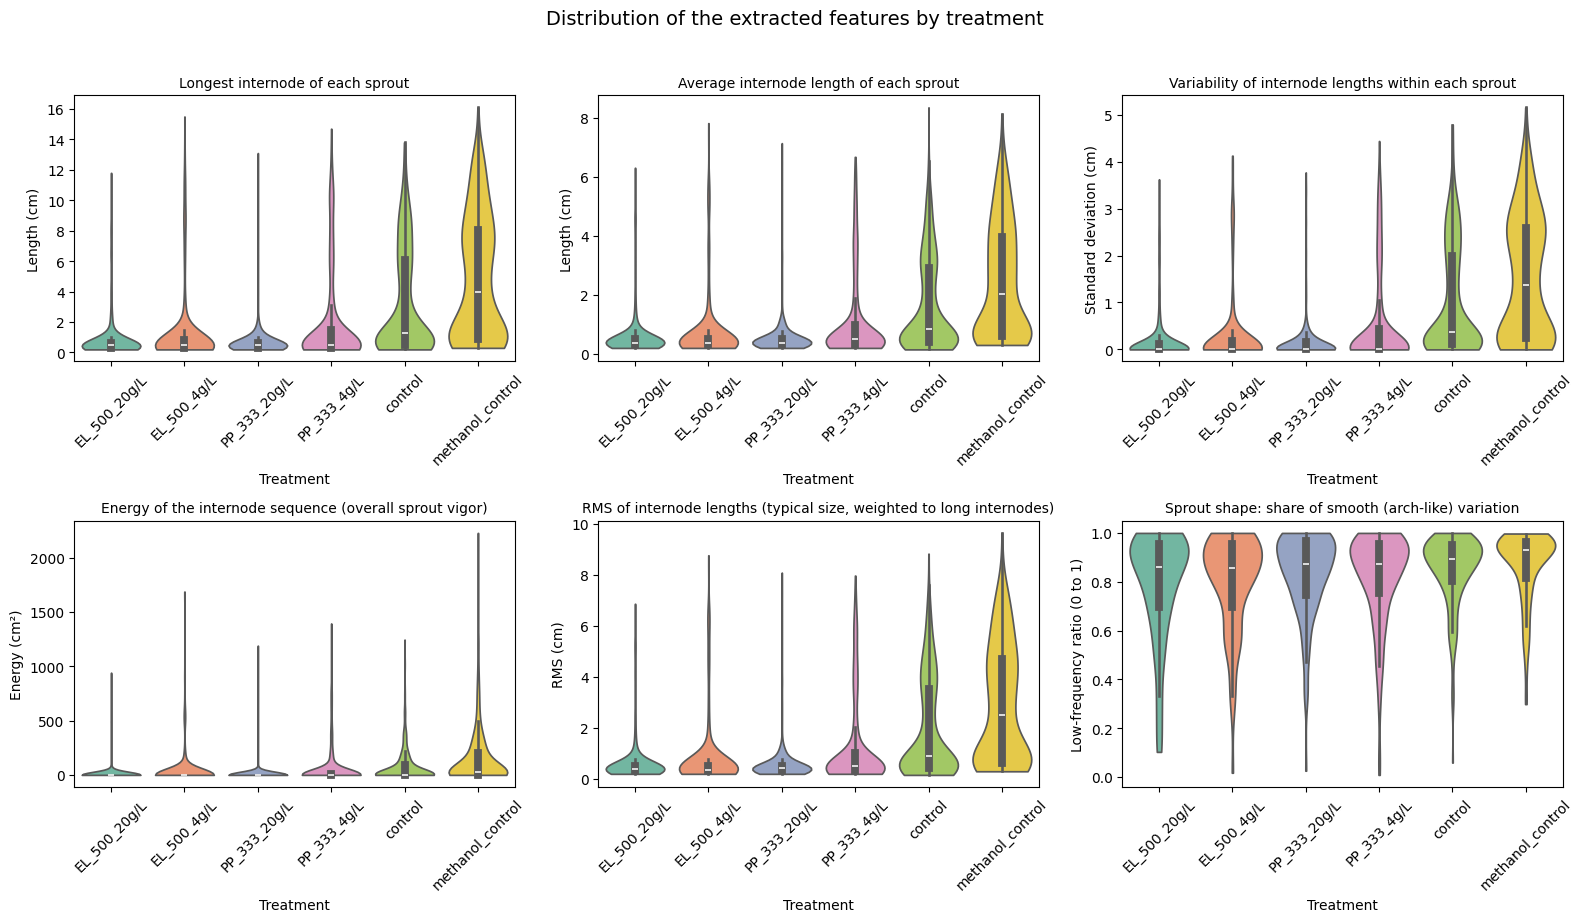

In [20]:
# Clear titles and axis labels for each feature, used in all the next plots

titles = {
    'max_length': 'Longest internode of each sprout',
    'mean_length': 'Average internode length of each sprout',
    'std_length': 'Variability of internode lengths within each sprout',
    'energy': 'Energy of the internode sequence (overall sprout vigor)',
    'rms': 'RMS of internode lengths (typical size, weighted to long internodes)',
    'low_freq_ratio': 'Sprout shape: share of smooth (arch-like) variation'
}

y_labels = {
    'max_length': 'Length (cm)',
    'mean_length': 'Length (cm)',
    'std_length': 'Standard deviation (cm)',
    'energy': 'Energy (cm²)',
    'rms': 'RMS (cm)',
    'low_freq_ratio': 'Low-frequency ratio (0 to 1)'
}

plt.figure(figsize=(16, 9))

for i, feature in enumerate(feature_cols):
    plt.subplot(2, 3, i + 1)
    sns.violinplot(x='TR', y=feature, data=df, hue='TR', palette='Set2', legend=False, cut=0)
    plt.title(titles[feature], fontsize=10)
    plt.xlabel('Treatment')
    plt.ylabel(y_labels[feature])
    plt.xticks(rotation=45)

plt.suptitle('Distribution of the extracted features by treatment', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

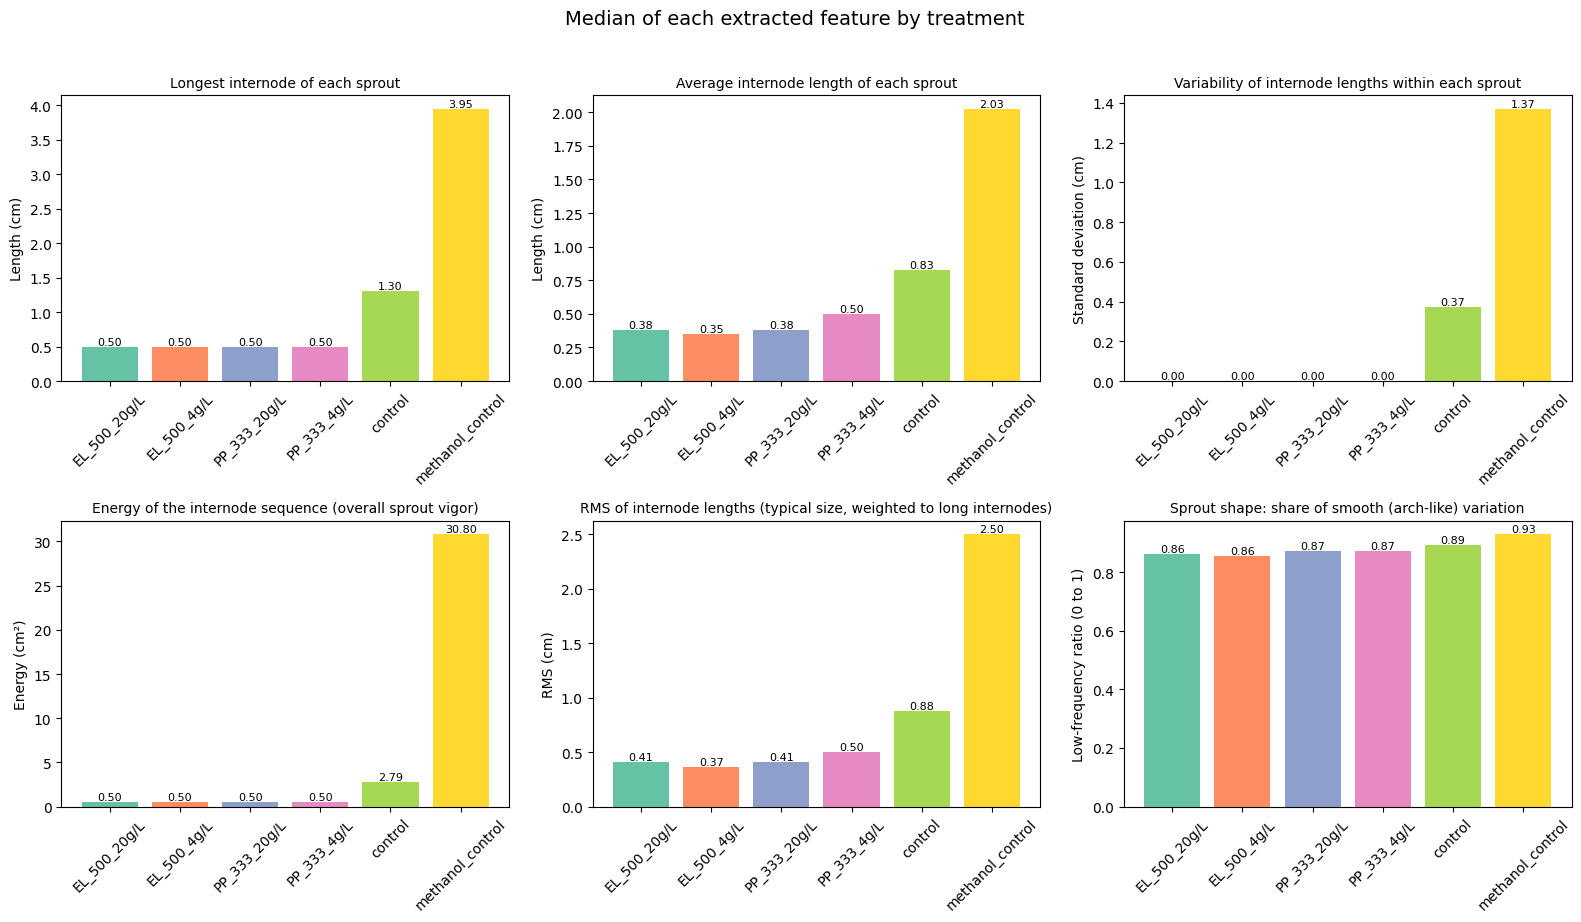

In [21]:
# Table with the median of each feature for each treatment
medians = df.groupby('TR', observed=True)[feature_cols].median()

# Bar plot of the medians (one subplot per feature)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, feature in enumerate(feature_cols):
    ax = axes[i // 3, i % 3]
    bars = ax.bar(medians.index.astype(str), medians[feature], color=sns.color_palette('Set2', 6))
    ax.bar_label(bars, fmt='%.2f', fontsize=8)
    ax.set_title(titles[feature], fontsize=10)
    ax.set_ylabel(y_labels[feature])
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Median of each extracted feature by treatment', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

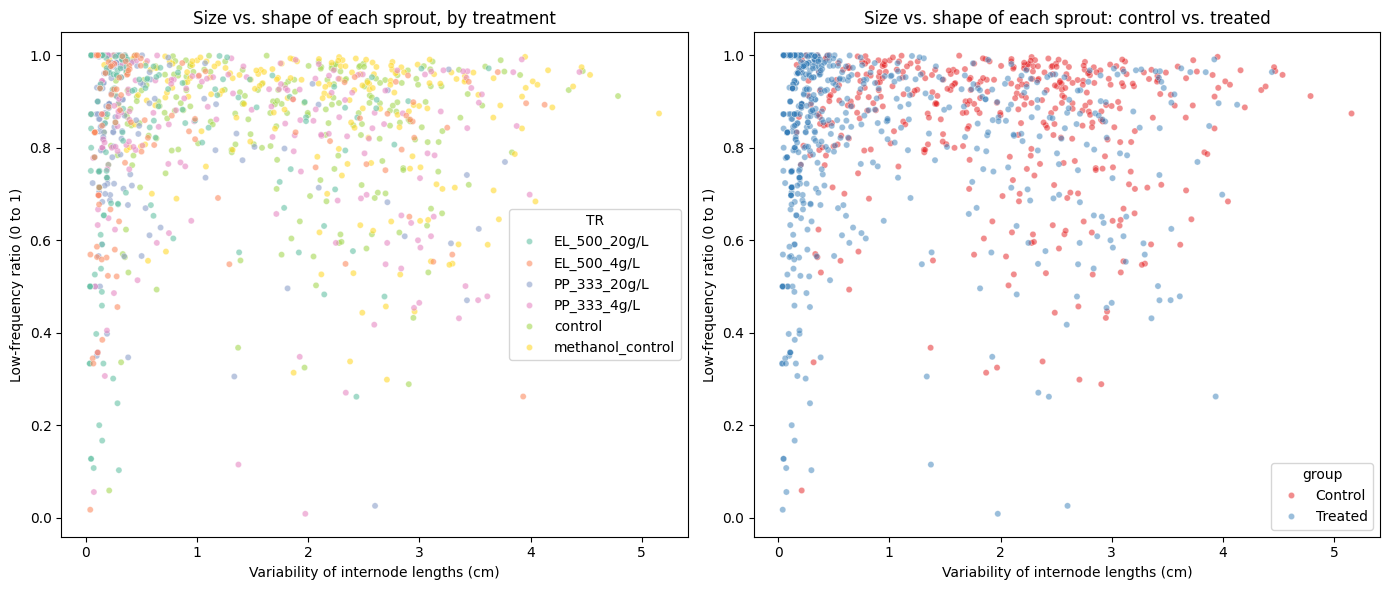

In [22]:
# Scatter plot of size (std_length) vs. shape (low_freq_ratio) to see if the groups separate

df['group'] = df['TR_code'].map(lambda x: 'Control' if x >= 4 else 'Treated')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(data=df, x='std_length', y='low_freq_ratio', hue='TR',
                palette='Set2', alpha=0.6, s=20, ax=axes[0])
axes[0].set_title('Size vs. shape of each sprout, by treatment')
axes[0].set_xlabel('Variability of internode lengths (cm)')
axes[0].set_ylabel('Low-frequency ratio (0 to 1)')

sns.scatterplot(data=df, x='std_length', y='low_freq_ratio', hue='group',
                palette='Set1', alpha=0.5, s=20, ax=axes[1])
axes[1].set_title('Size vs. shape of each sprout: control vs. treated')
axes[1].set_xlabel('Variability of internode lengths (cm)')
axes[1].set_ylabel('Low-frequency ratio (0 to 1)')

plt.tight_layout()
plt.show()

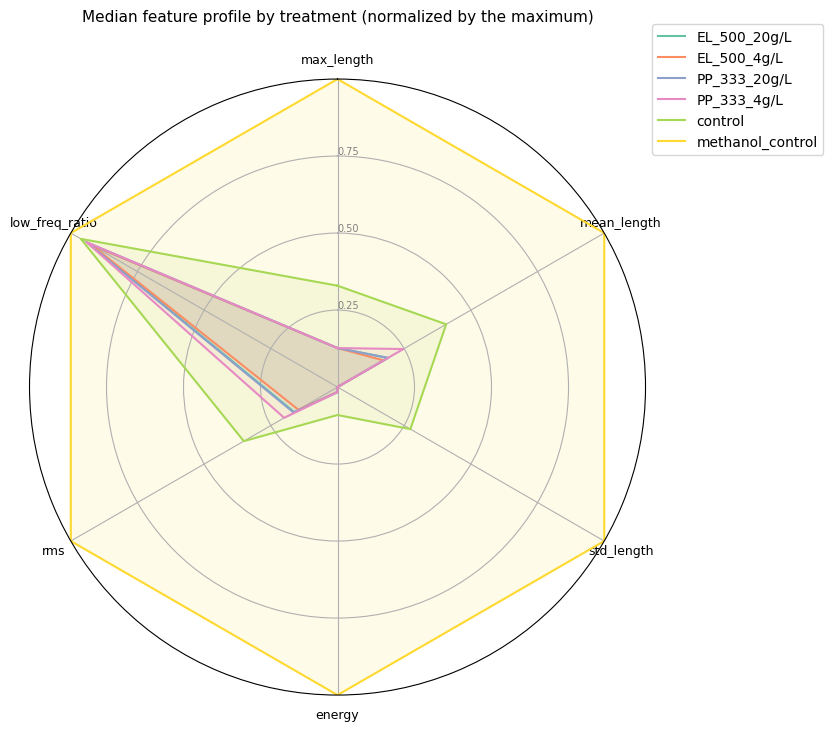

In [23]:
# Radar plot: median profile of each treatment, with each feature divided by its maximum (0 to 1)

radar = medians / medians.max()
radar = medians / medians.max()
categories = list(radar.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

plt.xticks(angles[:-1], categories, size=9)
ax.set_rlabel_position(0)
plt.yticks([0.25, 0.5, 0.75], ['0.25', '0.50', '0.75'], color='grey', size=7)
plt.ylim(0, 1)
colors = sns.color_palette('Set2', 6)
for i, treatment in enumerate(radar.index):
    values = radar.loc[treatment].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=1.5, label=str(treatment), color=colors[i])
    ax.fill(angles, values, color=colors[i], alpha=0.1)

plt.title('Median feature profile by treatment (normalized by the maximum)', size=11, y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

The plots show a clear difference in sprout size between treated and control groups. In the violin plots and bar charts, the four treated groups are concentrated near zero and have almost the same medians, for example 0.50 cm for maximum length, while the control group reaches 1.30 cm and methanol_control 3.95 cm. The median standard deviation is 0 in all treated groups, which means that more than half of these sprouts have one internode or all their internodes with the same length.

The shape of the sprouts changes very little. The low-frequency ratio has medians between 0.86 and 0.93 in all groups, and in the radar chart all polygons are close to the outer edge on that axis, while the treated groups form small, overlapping polygons near the center. In the scatter plots, treated sprouts are grouped on the left and controls spread to the right, but there is a wide area where both groups mix, and there is no separation on the shape axis.

In summary, the regulators reduce the size of the sprouts but barely change their shape, and the four treatments are very similar to each other. The best feature to separate the groups is the standard deviation of internode lengths and the worst is the low-frequency ratio, so a moderate separability is expected.

In [24]:
# Normality test (Shapiro-Wilk) for each treatment, then ANOVA or Kruskal-Wallis
# Same rule as in S5: if any group is not normal, use Kruskal-Wallis

alpha_normal = 0.05
alpha = 0.01

# Split the sprouts into the 6 treatments


for feature in feature_cols:
    groups = [df[df['TR_code'] == i][feature].dropna() for i in range(6)]
    shapiro_p = [shapiro(g).pvalue for g in groups]

    print(f'feature: {feature}')

    if min(shapiro_p) < alpha_normal:
        stat, p_value = kruskal(*groups)
        print('Non-normal distribution (using Kruskal-Wallis)')
    else:
        stat, p_value = f_oneway(*groups)
        print('Normal distribution (using ANOVA)')

    print(f'Statistic: {stat}')
    print(f'P-value: {p_value}')

    if p_value < alpha:
        print(f'There are statistically significant differences in {feature} among treatments.\n')
    else:
        print(f'There are no statistically significant differences in {feature} among treatments.\n')

feature: max_length
Non-normal distribution (using Kruskal-Wallis)
Statistic: 587.6501357855074
P-value: 9.421209296540116e-125
There are statistically significant differences in max_length among treatments.

feature: mean_length
Non-normal distribution (using Kruskal-Wallis)
Statistic: 497.87950347543324
P-value: 2.290650858254653e-105
There are statistically significant differences in mean_length among treatments.

feature: std_length
Non-normal distribution (using Kruskal-Wallis)
Statistic: 737.1404926145613
P-value: 4.5696856482998114e-157
There are statistically significant differences in std_length among treatments.

feature: energy
Non-normal distribution (using Kruskal-Wallis)
Statistic: 435.79191411641796
P-value: 5.6978632931123645e-92
There are statistically significant differences in energy among treatments.

feature: rms
Non-normal distribution (using Kruskal-Wallis)
Statistic: 515.0238285887259
P-value: 4.561247908339163e-109
There are statistically significant difference

The Shapiro-Wilk test showed that none of the six features follows a normal distribution in all treatment groups, as expected from the skewed distributions seen in the plots. For this reason, the Kruskal-Wallis test was used for all features. The five spatial features show significant differences between treatments, with very large statistics, from 436 to 737, and p-values close to zero. The standard deviation of internode lengths has the highest statistic, indicating that it is the feature that best distinguishes the treatments.

The low-frequency ratio is also significant, but its statistic is only 16.5, between 26 and 45 times smaller than those of the spatial features. With more than a thousand sprouts, even small differences can be significant, showing that statistical significance does not always mean a large effect. This agrees with the plots, where the shape of the sprouts changes very little. Finally, the Kruskal-Wallis test only shows that at least one treatment is different, not which one. The previous plots suggest that the main differences are between the control and treated groups.

In [25]:
# Compare the two control groups (control vs. methanol_control).
# Methanol is only the solvent, so in theory both groups should be the same.
# Kruskal-Wallis with 2 groups is used because the data are not normal

control = df[df['TR_code'] == 4]
methanol = df[df['TR_code'] == 5]

for feature in feature_cols:
    stat, p_value = kruskal(control[feature].dropna(), methanol[feature].dropna())
    print(f'feature: {feature}')
    print(f'Statistic: {stat}')
    print(f'P-value: {p_value}')
    if p_value < alpha:
        print('Significant difference between control and methanol_control.\n')
    else:
        print('No significant difference between control and methanol_control.\n')

feature: max_length
Statistic: 32.42812195582572
P-value: 1.2368358690837614e-08
Significant difference between control and methanol_control.

feature: mean_length
Statistic: 37.56437859646173
P-value: 8.844502399243133e-10
Significant difference between control and methanol_control.

feature: std_length
Statistic: 26.693985537478518
P-value: 2.3836231114637742e-07
Significant difference between control and methanol_control.

feature: energy
Statistic: 35.929384040369435
P-value: 2.045997688757645e-09
Significant difference between control and methanol_control.

feature: rms
Statistic: 38.43426285845788
P-value: 5.6629392217616e-10
Significant difference between control and methanol_control.

feature: low_freq_ratio
Statistic: 5.844004722235672
P-value: 0.015630212140214712
No significant difference between control and methanol_control.



Methanol is only the solvent for the growth regulators, so the control and methanol_control groups were expected to be the same. However, the five spatial features show significant differences between them, with p-values between 10⁻¹⁰ and 10⁻⁷, and methanol_control has larger sprouts, with a median maximum length of 3.95 cm compared to 1.30 cm in the control group. The low-frequency ratio shows no significant difference at the 0.01 level, so the shape of the sprouts is very similar in both groups.

A likely explanation is the design of the study. Each tree received only one treatment, and each group has only nine or ten trees. The trees are very different from each other: in the control groups, the median mean length per tree goes from 0.43 cm in tree Q23 to 4.85 cm in tree J25, more than ten times larger, and the trees of both groups are mixed across this range. Therefore, the difference between the two controls may depend on which trees ended up in each group more than on the methanol itself. This also shows a limitation of the study: sprouts from the same tree are not independent, which affects all the comparisons between treatments.

In [26]:
df.groupby('TR', observed=True)['TREE'].nunique() # Number of different trees in each treatment

,TREE
TR,
EL_500_20g/L,9
EL_500_4g/L,9
PP_333_20g/L,10
PP_333_4g/L,10
control,9
methanol_control,10


In [27]:
# Median of mean_length for each tree in the two control groups, sorted from lowest to highest

controls = df[df['TR_code'] >= 4]
controls.groupby('TREE', observed=True)['mean_length'].median().sort_values()

,mean_length
TREE,
Q23,0.433333
G29,0.500000
J29,0.566667
D19,0.566667
O20,0.833333
J13,1.050000
D20,1.233333
J8,1.250000
Q5,1.366667


In [28]:
# Fisher Discriminant Ratio (FDR) for each feature, calculated one feature at a time.
# FDR = dispersion between treatments / dispersion within treatments.
# A high FDR means the groups are far apart and compact.

fdr = {}

for feature in feature_cols:
    data = df[['TR_code', feature]].dropna()
    overall_mean = data[feature].mean()
    group_means = data.groupby('TR_code')[feature].mean()

    within = 0
    between = 0
    for k, mean_k in group_means.items():
        x = data[data['TR_code'] == k][feature]
        within += np.sum((x - mean_k)**2)
        between += len(x) * (mean_k - overall_mean)**2

    fdr[feature] = between / within

pd.Series(fdr).sort_values(ascending=False)

,0
std_length,0.274816
max_length,0.234851
rms,0.230322
mean_length,0.213200
energy,0.064813
low_freq_ratio,0.023032



# *Data separability*

To go from showing statistical differences to evaluating how well the sprouts can be distinguished one by one, the area under the ROC curve (ROC-AUC) was calculated for each feature using a one-versus-rest approach, followed by a comparison between the combined control and treated groups. Then, a simple classification rule was defined using the standard deviation of internode lengths, where values above a threshold are classified as controls, and this rule was evaluated with accuracy, precision, recall, and F1. An AUC of 0.5 represents random chance, values above 0.7 are considered acceptable, and 1.0 indicates perfect separation. If the AUC is below 0.5, it is replaced by 1 − AUC, because this means the feature separates the groups in the opposite direction.

In [29]:
# Names of the treatments for each TR_code (like the species dictionary in S5)
treatments = {0: 'EL_500_20g/L', 1: 'EL_500_4g/L', 2: 'PP_333_20g/L',
              3: 'PP_333_4g/L', 4: 'control', 5: 'methanol_control'}

# Empty table: one row per feature, one column per treatment
auc_table = pd.DataFrame(index=feature_cols, columns=list(treatments.values()), dtype=float)

# AUC one-versus-rest: each treatment (1) against all the others (0)
for feature in feature_cols:
    data = df[['TR_code', feature]].dropna()
    for class_idx, name in treatments.items():
        target = np.where(data['TR_code'] == class_idx, 1, 0)
        auc_score = roc_auc_score(target, data[feature])
        # If AUC < 0.5, use 1 - AUC (the feature separates in the opposite direction)
        auc_table.loc[feature, name] = auc_score if auc_score >= .5 else (1 - auc_score)

auc_table.round(3)

,EL_500_20g/L,EL_500_4g/L,PP_333_20g/L,PP_333_4g/L,control,methanol_control
max_length,0.632,0.601,0.612,0.502,0.707,0.801
mean_length,0.615,0.591,0.615,0.515,0.668,0.796
std_length,0.637,0.602,0.620,0.522,0.757,0.796
energy,0.613,0.576,0.603,0.509,0.644,0.793
rms,0.617,0.601,0.613,0.517,0.670,0.804
low_freq_ratio,0.549,0.546,0.505,0.529,0.510,0.581


In [30]:
# New column: 1 = control (TR_code 4 and 5), 0 = treated (TR_code 0 to 3)
df['is_control'] = np.where(df['TR_code'] >= 4, 1, 0)

# AUC of each feature to separate control from treated sprouts
binary_auc = {}
for feature in feature_cols:
    data = df[['is_control', feature]].dropna()
    auc_score = roc_auc_score(data['is_control'], data[feature])
    binary_auc[feature] = auc_score if auc_score >= .5 else (1 - auc_score)

# Sort from best to worst
pd.Series(binary_auc).sort_values(ascending=False)

,0
std_length,0.815726
max_length,0.784290
rms,0.760705
mean_length,0.755351
energy,0.737434
low_freq_ratio,0.557922


In [31]:
y_true = df['is_control']
results = []

for threshold in [0.3, 0.5, 0.75, 1.0]:
    y_pred = np.where(df['std_length'] > threshold, 1, 0)

    TP = np.sum((y_pred == 1) & (y_true == 1))   # control predicted as control
    TN = np.sum((y_pred == 0) & (y_true == 0))   # treated predicted as treated
    FP = np.sum((y_pred == 1) & (y_true == 0))   # treated predicted as control
    FN = np.sum((y_pred == 0) & (y_true == 1))   # control predicted as treated

    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * precision * recall / (precision + recall)

    results.append({'threshold': threshold, 'TP': TP, 'TN': TN, 'FP': FP, 'FN': FN,
                    'accuracy': accuracy, 'precision': precision, 'recall': recall, 'F1': f1})

pd.DataFrame(results).round(3)

,threshold,TP,TN,FP,FN,accuracy,precision,recall,F1
0,0.30,420,1750,357,268,0.776,0.541,0.610,0.573
1,0.50,368,1848,259,320,0.793,0.587,0.535,0.560
2,0.75,333,1890,217,355,0.795,0.605,0.484,0.538
3,1.00,304,1916,191,384,0.794,0.614,0.442,0.514


AUC results: the AUC shows a moderate separation between control and treated sprouts, reaching 0.82 with std_length. However, the ability of the features to distinguish each specific treatment from the rest is weak, with AUC values between 0.50 and 0.64 for the treated groups, which reflects a high overlap between the different compounds and doses. In all cases, std_length is the best feature, while low_freq_ratio barely separates the groups.

Classification rule based on std_length: accuracy is misleading in this case. Although the rule reaches values from 0.78 to 0.80, a baseline that classifies all sprouts as treated, the majority class, already reaches 0.754. Taking control as the positive class, increasing the threshold raises the precision from 0.54 to 0.61, but the recall drops from 0.61 to 0.44. The best balance is found with a threshold of 0.3, with a maximum F1-score of 0.573. This explains the classification errors:
- The recall drops because a stricter rule leaves out real controls with low variability, that is, short control sprouts.
- False positives are treated sprouts that did grow, the outliers, which the rule classified as control because of their high standard deviation.
- False negatives are control sprouts with naturally reduced growth that the rule classified as treated.

Conclusion and limitations: the analysis shows that the growth regulators reduce the size of the sprouts but barely change the shape of their growth pattern. The results must be interpreted considering an important limitation of the maple trees used in the study: each treatment has only 9 or 10 trees, and the many sprouts taken from the same tree are not independent of each other. In addition, there is a high variability between trees, with median values in the controls ranging from 0.43 to 4.85 cm, which could explain part of the observed differences, including the difference between the two control groups.